# Logarithmic Potentials (Metropolis–Hastings)

Rather than changing who trades with whom, this notebook keeps the DY pairing and instead accepts or rejects each proposed exchange with a Metropolis probability based on a potential $U(w)$. The simulation is `MH_simulate` in `wealth_dist/metropolis.py`.

## Set Up:
- $N$ agents with wealth $m$, leading to total wealth $M = Nm$
- Randomly select two agents (winner $i$ and loser $j$)
- Choose $\Delta m \sim U(0, m)$
- Propose $w_i' = w_i + \Delta m$ and $w_j' = w_j - \Delta m$
- Compute the change in the total interaction potential,
$$ \Delta U = U(w_i') + U(w_j') - U(w_i) - U(w_j) $$
- Accept the proposed exchange with Metropolis probability
$$ P_{\rm acc} = \min(1, e^{-\beta\Delta U} )$$

The exchange occurs only if $\Delta m \le w_j$, and then with probability $P_{\rm acc}$.

We first consider $U(w) = \log(w)$. The algebra gives:
$$
P_{\mathrm{acc}}=1
\iff
w_j-w_i\le\Delta m.
\iff 
w_j - \Delta m \le w_i 
\iff 
w_j' \le w_i ' - \Delta m 
\iff 
\Delta m \le w_i' - w_j '
$$

That is, a trade is accepted automatically exactly when the loser's wealth minus the winner's wealth is at most the amount exchanged. Automatically accepted trades therefore never reduce inequality within the pair. For $U(w) = -\log(w)$ the inequality flips, and trades that reduce inequality are favoured instead.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from wealth_dist.plotting import plot_simulation_results, plot_ccdf
from wealth_dist.metropolis import MH_simulate
from wealth_dist.stats_analysis import pareto_tail_fits

np.random.seed()  # for reproducibility

In [2]:
eps = 1e-6 # avoids log(0)

def U1(x):
    return np.log(x + eps)

def U2(x):
    return -np.log(x + eps)

In [3]:
N = 10000 #agents
m = 100 #wealth
sims = 100000
beta = 1

log_res = MH_simulate(N, m, sims, count = 0.01, beta = beta, U = U1)
minuslog_res = MH_simulate(N, m, sims, count = 0.01, beta = beta, U = U2)

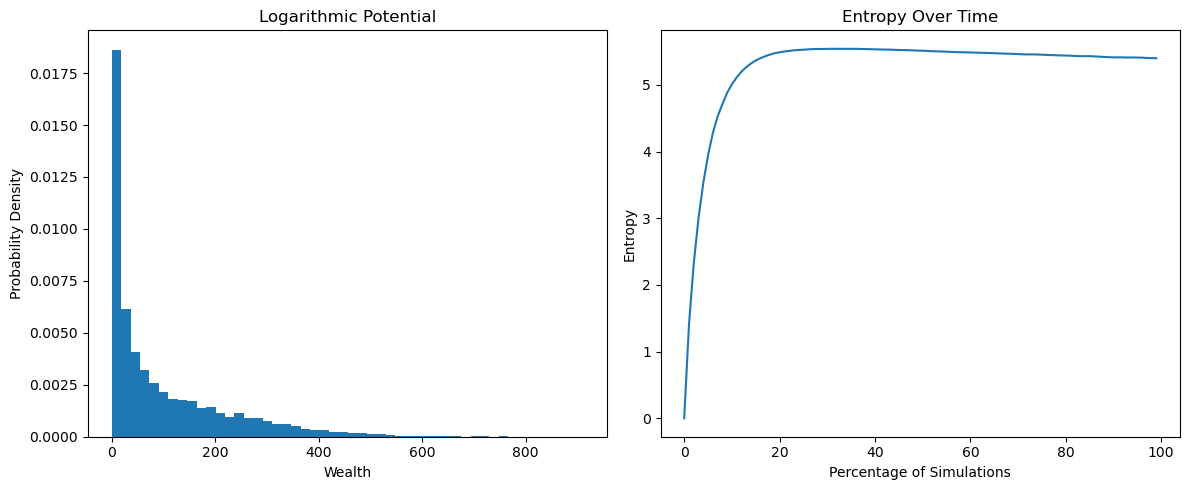

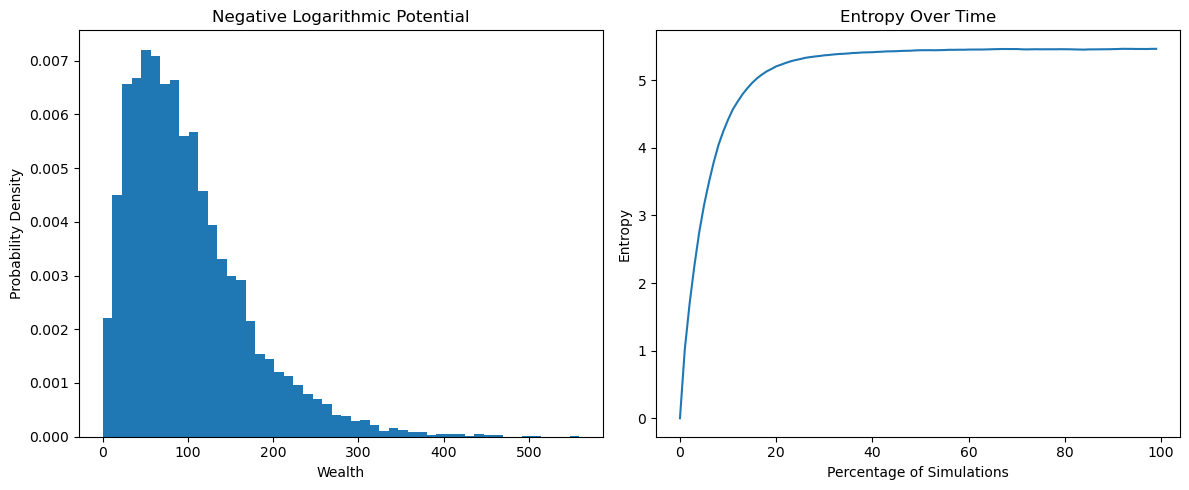

In [4]:
plot_simulation_results(log_res, bins = 50, title = "Logarithmic Potential")
plot_simulation_results(minuslog_res, bins = 50, title = "Negative Logarithmic Potential")

The negative logarithmic potential favours equality and gives a shorter, roughly lognormal-looking distribution, while $U(w) = \log(w)$ produces the longer tail. Pareto fits to the tail of the $\log(w)$ case follow (`alpha` is the exponent of the fitted CCDF).

In [5]:
fitting = pareto_tail_fits(log_res[0])


Top 10% tail
xmin = 282.16686006569233
n_tail = 1000
alpha = 3.6453969462650164
KS = 0.08308544297934889
p-value = 1.8749700554803881e-06

Top 5% tail
xmin = 354.67347110816803
n_tail = 500
alpha = 4.694052617978869
KS = 0.08639431356558147
p-value = 0.0010726234164406124

Top 2.5% tail
xmin = 424.8990196605509
n_tail = 250
alpha = 6.213941611927326
KS = 0.08635397138332229
p-value = 0.04523351037455803

Top 1% tail
xmin = 497.0872044264548
n_tail = 100
alpha = 7.640250929149778
KS = 0.0733525405600054
p-value = 0.6280619603084097


The CCDF of the $\log(w)$ case on linear, semi-log and log-log axes, for the whole population and for the top 5% and 1%.

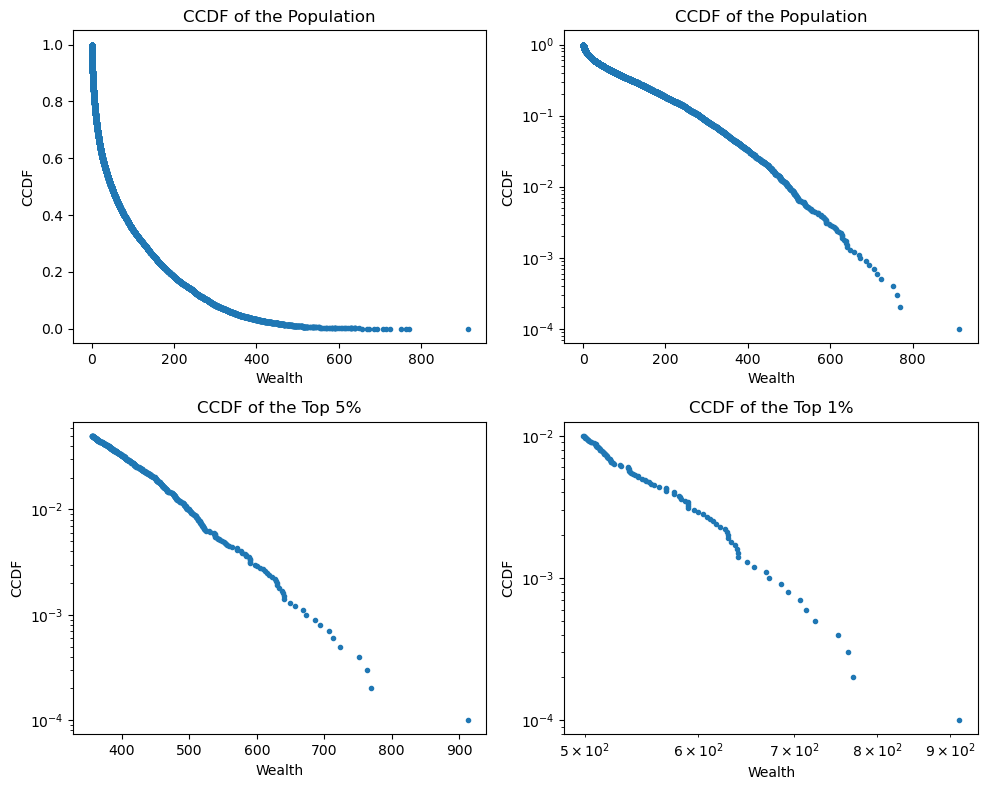

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs = axs.ravel()
plot_ccdf(log_res[0], pct = None, reg = False, xlog = False, ylog = False, ax=axs[0])
plot_ccdf(log_res[0], pct = None, reg = False, xlog = False, ylog = True, ax=axs[1])
plot_ccdf(log_res[0], pct = 95, reg = False, xlog = False, ylog = True, ax=axs[2])
plot_ccdf(log_res[0], pct = 99, reg = False, xlog = True, ylog = True, ax=axs[3])
plt.tight_layout()
plt.show()

The fitted exponent again drifts with the threshold, so $\log(w)$ on its own does not give a clean power law at this scale. `06_unified_log_potential.ipynb` introduces a finite scale $w_0$, so the potential is linear for small wealth and logarithmic for large wealth.